# Intel Image Classification with SIFT + Machine Learning
Classify scenes into 6 classes (buildings, forest, glacier, mountain, sea, street) using
SIFT features, a Bag of Visual Words vector, and scikit-learn models.

# Intel Image Classification with SIFT + Machine Learning
Run all cells. You will be asked for your Kaggle username and API key once (they are NOT saved in the notebook).
Everything (model, plots, app, README) is saved to your Google Drive in `MyDrive/intel-image-classification`.

## 0. Setup: Kaggle login, Google Drive, dataset download

In [1]:
import os
from getpass import getpass

# --- Kaggle login (typed here, not stored in the notebook) ---
username = input("Kaggle username (leave empty if your key starts with KGAT_): ").strip()
key = getpass("Kaggle API key: ").strip()
if username:
    os.environ["KAGGLE_USERNAME"] = username
    os.environ["KAGGLE_KEY"] = key
else:
    os.environ["KAGGLE_API_TOKEN"] = key

# --- Google Drive: all outputs go here ---
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/intel-image-classification"
except ImportError:
    OUT_DIR = "intel-image-classification"   # not on Colab: save in the current folder
os.makedirs(OUT_DIR, exist_ok=True)
print("Outputs will be saved to:", OUT_DIR)

In [2]:
!pip install -q kagglehub opencv-python seaborn scikit-learn joblib
import kagglehub
path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification


## 1. Load Dataset

In [3]:
import os
import random
import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

random.seed(42)
np.random.seed(42)

In [4]:
# The dataset already comes split into train and test folders, with one sub-folder per class:
#   seg_train/seg_train/<class>/*.jpg   and   seg_test/seg_test/<class>/*.jpg
# This finds those folders automatically inside the downloaded dataset.
def find_split(root, name):
    for folder, subs, files in os.walk(root):
        if os.path.basename(folder) == name and "buildings" in subs:
            return folder
    raise FileNotFoundError(name)

TRAIN_DIR = find_split(path, "seg_train")
TEST_DIR = find_split(path, "seg_test")

CLASSES = sorted(os.listdir(TRAIN_DIR))
print("Classes:", CLASSES)

def list_images(folder):
    paths, labels = [], []
    for idx, name in enumerate(CLASSES):
        class_folder = os.path.join(folder, name)
        for file in os.listdir(class_folder):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                paths.append(os.path.join(class_folder, file))
                labels.append(idx)
    return paths, np.array(labels)

train_paths, y_train = list_images(TRAIN_DIR)
test_paths, y_test = list_images(TEST_DIR)
print("Train images:", len(train_paths))
print("Test images:", len(test_paths))
print(pd.Series(y_train).map(dict(enumerate(CLASSES))).value_counts())

Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Train images: 14034
Test images: 3000
mountain     2512
glacier      2404
street       2382
sea          2274
forest       2271
buildings    2191
Name: count, dtype: int64


## 2. Visualize Sample Images

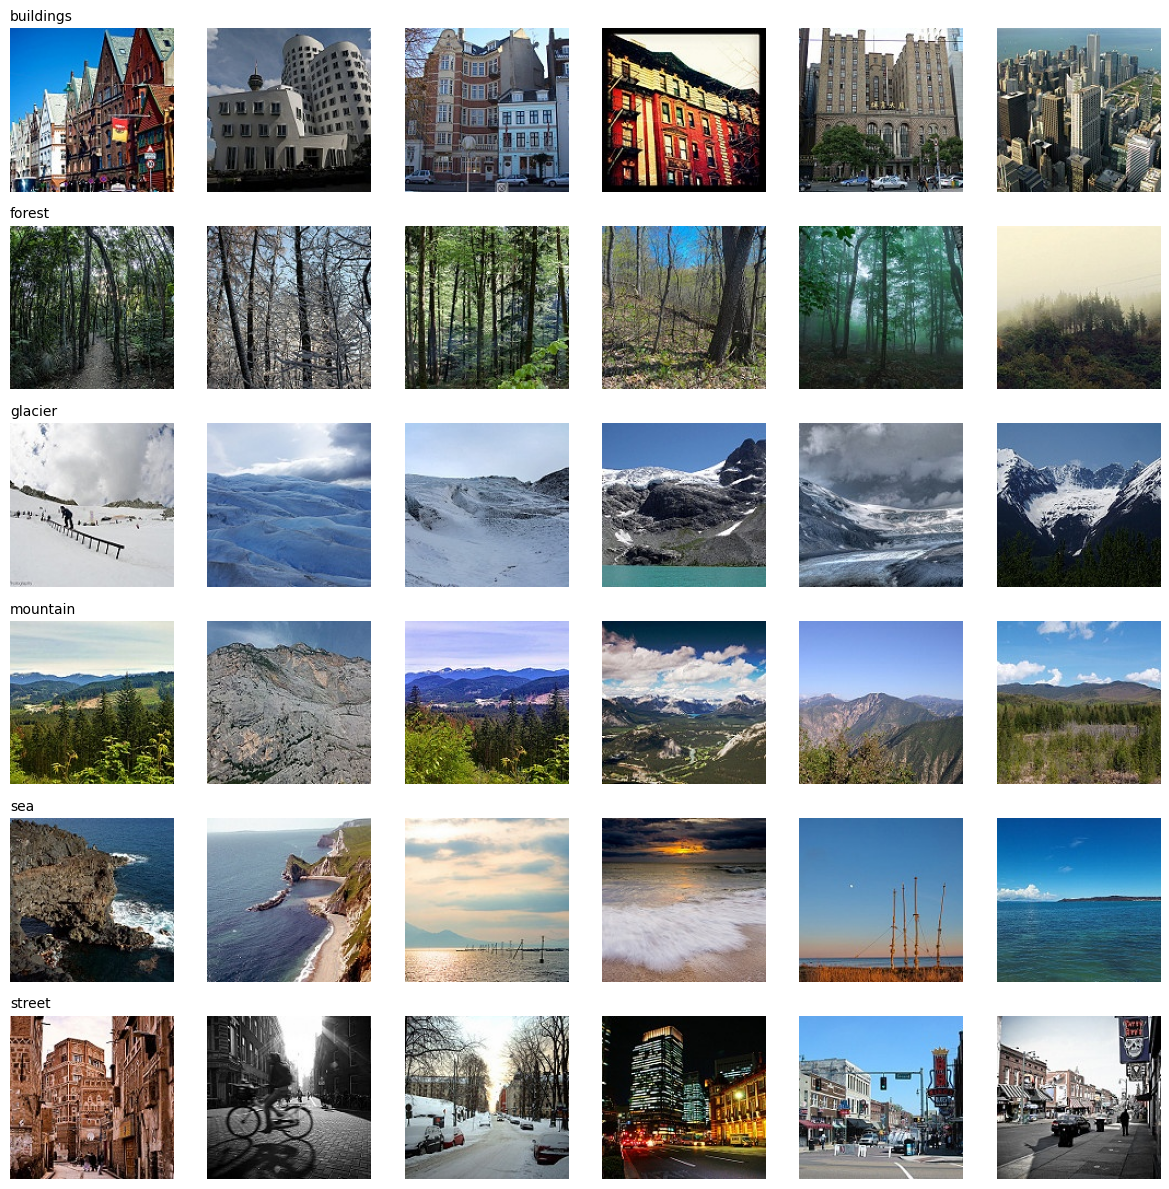

In [5]:
N_SHOW = 6   # images per class
fig, axes = plt.subplots(len(CLASSES), N_SHOW, figsize=(2 * N_SHOW, 2 * len(CLASSES)))
for row, name in enumerate(CLASSES):
    class_paths = [p for p, l in zip(train_paths, y_train) if l == row]
    chosen = random.sample(class_paths, N_SHOW)
    for col, path in enumerate(chosen):
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # cv2 loads as BGR
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(name, loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "sample_images.png"), dpi=150, bbox_inches="tight")
plt.show()

## 3. Preprocessing
Resize to 128x128 and convert to grayscale (SIFT works on grayscale images).

In [6]:
IMG_SIZE = 128

def preprocess(img_bgr):
    img = cv2.resize(img_bgr, (IMG_SIZE, IMG_SIZE))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return gray

def load_and_preprocess(paths):
    images = []
    for path in paths:
        img = cv2.imread(path)
        if img is None:
            images.append(np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8))
        else:
            images.append(preprocess(img))
    return images

X_train_imgs = load_and_preprocess(train_paths)
X_test_imgs = load_and_preprocess(test_paths)
print("Done. Image shape:", X_train_imgs[0].shape)

Done. Image shape: (128, 128)


## 4. Feature Extraction (SIFT + Bag of Visual Words)
1. Extract SIFT descriptors from every image (each descriptor has 128 numbers).
2. Cluster a sample of the training descriptors with KMeans -> `K` "visual words".
3. For each image, count how many of its descriptors fall in each visual word -> a vector of length `K`.

In [7]:
sift = cv2.SIFT_create()
K = 100   # size of the visual vocabulary = length of the final feature vector

def get_descriptors(gray):
    keypoints, descriptors = sift.detectAndCompute(gray, None)
    return descriptors   # can be None if no keypoints were found

train_desc = [get_descriptors(img) for img in X_train_imgs]
test_desc = [get_descriptors(img) for img in X_test_imgs]
print("Images with no descriptors (train):", sum(d is None for d in train_desc))

Images with no descriptors (train): 16


In [8]:
# Build the vocabulary using at most 200000 random descriptors from the train set
all_desc = np.vstack([d for d in train_desc if d is not None])
print("Total train descriptors:", all_desc.shape)
if len(all_desc) > 200000:
    pick = np.random.choice(len(all_desc), 200000, replace=False)
    all_desc = all_desc[pick]

kmeans = MiniBatchKMeans(n_clusters=K, random_state=42, batch_size=2048, n_init=3)
kmeans.fit(all_desc)

def to_histogram(descriptors):
    hist = np.zeros(K)
    if descriptors is not None:
        words = kmeans.predict(descriptors.astype(np.float32))
        for w in words:
            hist[w] += 1
        hist = hist / hist.sum()   # normalise so images with more keypoints are comparable
    return hist

X_train = np.array([to_histogram(d) for d in train_desc])
X_test = np.array([to_histogram(d) for d in test_desc])
print("Feature matrix:", X_train.shape, X_test.shape)

Total train descriptors: (1886603, 128)
Feature matrix: (14034, 100) (3000, 100)


## 5. Model Training
Four models are compared. Each one is wrapped in a pipeline with a `StandardScaler`.

In [9]:
models = {
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, probability=True, random_state=42)),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
    "k-NN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
}

results = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results[name] = accuracy_score(y_test, pred)
    print(f"{name}: test accuracy = {results[name]:.4f}")

SVM: test accuracy = 0.5277
Random Forest: test accuracy = 0.5400
k-NN: test accuracy = 0.4383
Logistic Regression: test accuracy = 0.5323


## 6. Evaluation

Random Forest          0.540000
Logistic Regression    0.532333
SVM                    0.527667
k-NN                   0.438333
Name: Test accuracy, dtype: float64


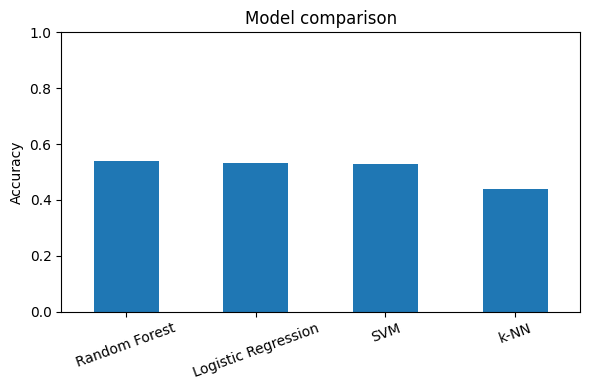

In [10]:
result_table = pd.Series(results, name="Test accuracy").sort_values(ascending=False)
print(result_table)

result_table.plot(kind="bar", figsize=(6, 4), ylim=(0, 1))
plt.title("Model comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "model_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

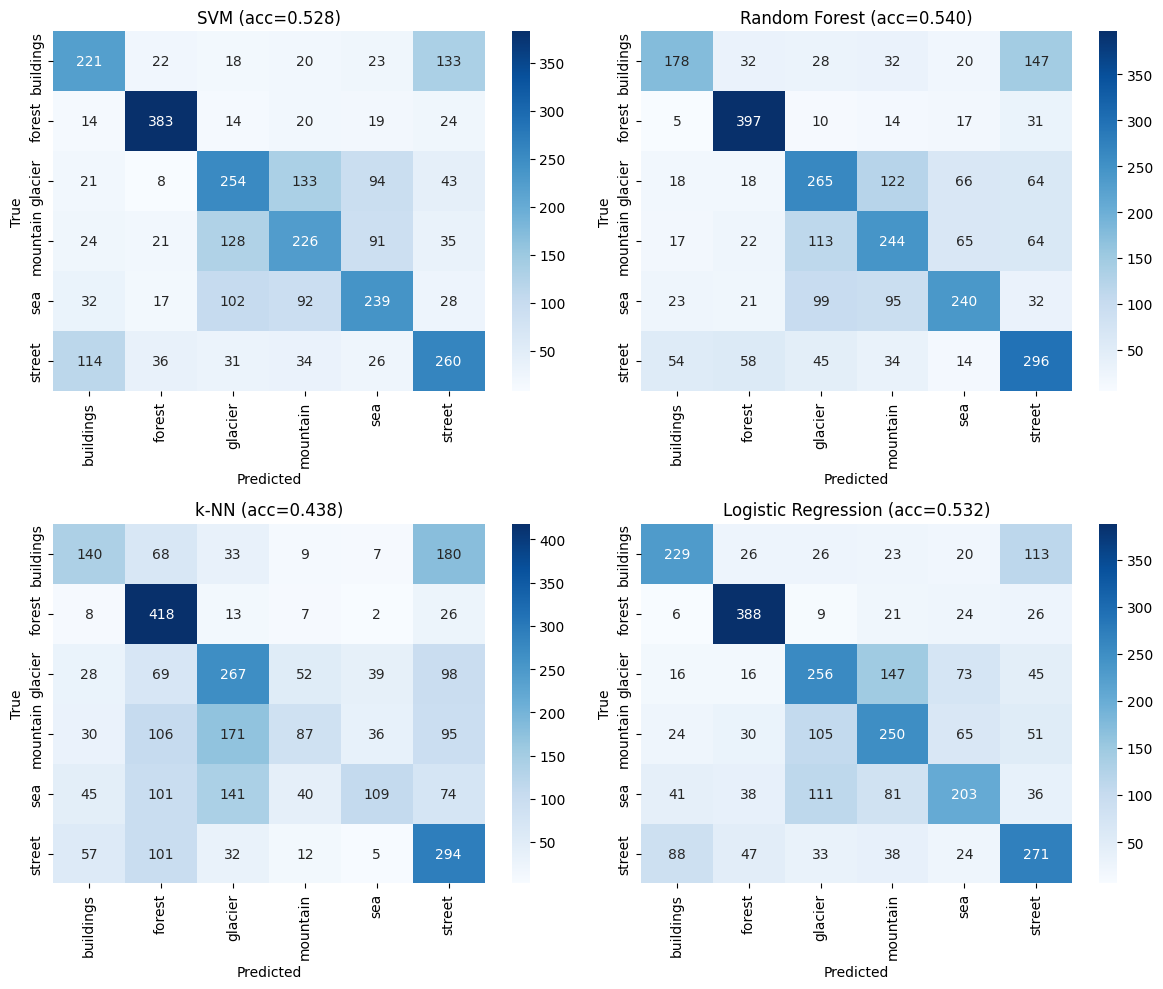

Best model: Random Forest
              precision    recall  f1-score   support

   buildings       0.60      0.41      0.49       437
      forest       0.72      0.84      0.78       474
     glacier       0.47      0.48      0.48       553
    mountain       0.45      0.46      0.46       525
         sea       0.57      0.47      0.52       510
      street       0.47      0.59      0.52       501

    accuracy                           0.54      3000
   macro avg       0.55      0.54      0.54      3000
weighted avg       0.54      0.54      0.54      3000



In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, pred) in zip(axes.flatten(), predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f"{name} (acc={results[name]:.3f})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confusion_matrices.png"), dpi=150, bbox_inches="tight")
plt.show()

best_name = max(results, key=results.get)
print("Best model:", best_name)
print(classification_report(y_test, predictions[best_name], target_names=CLASSES))

## 7. Save Best Model
The vocabulary (KMeans) must be saved too, because the Streamlit app needs it to build the feature vector.

In [12]:
MODEL_DIR = os.path.join(OUT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)
MODEL_PATH = os.path.join(MODEL_DIR, "best_model.joblib")
bundle = {
    "model": models[best_name],
    "kmeans": kmeans,
    "classes": CLASSES,
    "img_size": IMG_SIZE,
    "k": K,
    "model_name": best_name,
    "test_accuracy": results[best_name],
}
joblib.dump(bundle, MODEL_PATH, compress=3)
print("Saved", MODEL_PATH)

Saved /content/drive/MyDrive/intel-image-classification/models/best_model.joblib


In [13]:
# Quick check: load the saved file and predict one test image
saved = joblib.load(MODEL_PATH)
i = random.randrange(len(test_paths))
gray = preprocess(cv2.imread(test_paths[i]))
desc = sift.detectAndCompute(gray, None)[1]
hist = to_histogram(desc).reshape(1, -1)
probs = saved["model"].predict_proba(hist)[0]
print("True:", CLASSES[y_test[i]], "| Predicted:", saved["classes"][probs.argmax()], f"({probs.max():.2%})")

True: buildings | Predicted: forest (66.00%)


## 8. Save project files (app, README, requirements) to Google Drive

In [14]:
APP_CODE = """import cv2
import joblib
import numpy as np
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Intel Image Classifier", page_icon="🏞️")


@st.cache_resource
def load_bundle():
    return joblib.load("models/best_model.joblib")


bundle = load_bundle()
model = bundle["model"]
kmeans = bundle["kmeans"]
classes = bundle["classes"]
img_size = bundle["img_size"]
k = bundle["k"]
sift = cv2.SIFT_create()


def preprocess(img_bgr):
    img = cv2.resize(img_bgr, (img_size, img_size))
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


def extract_features(gray):
    keypoints, descriptors = sift.detectAndCompute(gray, None)
    if descriptors is None:
        return None, 0
    words = kmeans.predict(descriptors.astype(np.float32))
    hist = np.bincount(words, minlength=k).astype(float)
    return (hist / hist.sum()).reshape(1, -1), len(keypoints)


st.title("Intel Image Classifier")
st.write("Upload a photo and the model will predict one of: " + ", ".join(classes) + ".")
st.caption(f"Model: {bundle['model_name']} | test accuracy: {bundle['test_accuracy']:.2%} | SIFT + Bag of Visual Words")

uploaded = st.file_uploader("Choose an image", type=["jpg", "jpeg", "png"])

if uploaded is not None:
    file_bytes = np.frombuffer(uploaded.read(), dtype=np.uint8)
    img_bgr = cv2.imdecode(file_bytes, cv2.IMREAD_COLOR)

    if img_bgr is None:
        st.error("Could not read this image. Please try another file.")
    else:
        st.image(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), caption="Uploaded image", use_container_width=True)
        features, n_keypoints = extract_features(preprocess(img_bgr))

        if features is None:
            st.warning("No SIFT keypoints were found in this image, so it cannot be classified.")
        else:
            probs = model.predict_proba(features)[0]
            best = int(np.argmax(probs))
            st.success(f"Prediction: **{classes[best]}**  (confidence: {probs[best]:.1%})")
            st.caption(f"{n_keypoints} SIFT keypoints used")
            chart = pd.DataFrame({"class": classes, "probability": probs}).set_index("class")
            st.bar_chart(chart)
"""

REQUIREMENTS = """opencv-python-headless
numpy
pandas
scikit-learn
matplotlib
seaborn
joblib
streamlit
jupyter
"""

with open(os.path.join(OUT_DIR, "app.py"), "w") as f:
    f.write(APP_CODE)
with open(os.path.join(OUT_DIR, "requirements.txt"), "w") as f:
    f.write(REQUIREMENTS)

rows = "\n".join(f"| {n} | {a:.2%} |" for n, a in result_table.items())
README = f"""# Intel Image Classification (SIFT + Machine Learning + Streamlit)

## Project overview
An end-to-end image classification system that classifies natural scenes into 6 classes
(buildings, forest, glacier, mountain, sea, street) without deep learning.

Pipeline: load images -> resize to 128x128 + grayscale -> SIFT descriptors ->
Bag of Visual Words (KMeans, {K} words) -> fixed-size vector -> scikit-learn classifiers ->
evaluation -> save best model -> Streamlit app for live prediction.

## Dataset
[Intel Image Classification (Kaggle)](https://www.kaggle.com/datasets/puneet6060/intel-image-classification)
- About 25,000 images (150x150, RGB) in 6 classes, split into `seg_train` and `seg_test`.
- Classes: buildings, forest, glacier, mountain, sea, street.

## Tools used
OpenCV (image loading, SIFT), scikit-learn (KMeans, SVM, Random Forest, k-NN, Logistic Regression),
NumPy / pandas, matplotlib / seaborn, joblib, Streamlit.

## Project structure
```
notebooks/intel_image_classification.ipynb
app.py
models/best_model.joblib
requirements.txt
```

## How to run
Training: open the notebook in Google Colab or Jupyter and run all cells
(it downloads the dataset with kagglehub and saves the best model to `models/best_model.joblib`).

Inference:
```
pip install -r requirements.txt
streamlit run app.py
```
Upload an image to see the predicted class and confidence score.

## Results
| Model | Test accuracy |
|---|---|
{rows}

Best model: **{best_name}** ({results[best_name]:.2%})

![Confusion matrices](confusion_matrices.png)

## Screenshots
Add a screenshot of the Streamlit app here, for example: `![App](screenshots/app.png)`
"""
with open(os.path.join(OUT_DIR, "README.md"), "w") as f:
    f.write(README)

print("Everything is saved in:", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print(" -", name)

Everything is saved in: /content/drive/MyDrive/intel-image-classification
 - README.md
 - app.py
 - confusion_matrices.png
 - model_comparison.png
 - models
 - requirements.txt
 - sample_images.png


In [ ]:
import os, json, shutil

# 1. move plots into results/
RESULTS_DIR = os.path.join(OUT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)
for name in ["sample_images.png", "model_comparison.png", "confusion_matrices.png"]:
    src = os.path.join(OUT_DIR, name)
    if os.path.exists(src):
        shutil.move(src, os.path.join(RESULTS_DIR, name))

# 2. train.py (same pipeline as the notebook, as a script)
TRAIN_CODE = r'''# Train SIFT + Bag-of-Visual-Words classifiers on the Intel Image Classification dataset.
# Usage:  python train.py --data intel_data --out models
# (--data is the folder that contains seg_train and seg_test, anywhere inside it)

import argparse
import os
import random

import cv2
import joblib
import numpy as np
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

IMG_SIZE = 128
K = 100


def find_split(root, name):
    for folder, subs, files in os.walk(root):
        if os.path.basename(folder) == name and "buildings" in subs:
            return folder
    raise FileNotFoundError(name)


def load_split(folder, classes, sift):
    # returns SIFT descriptors and labels for every image in the folder
    all_desc, labels = [], []
    for idx, name in enumerate(classes):
        class_folder = os.path.join(folder, name)
        for file in os.listdir(class_folder):
            if not file.lower().endswith((".jpg", ".jpeg", ".png")):
                continue
            img = cv2.imread(os.path.join(class_folder, file))
            if img is None:
                continue
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            desc = sift.detectAndCompute(gray, None)[1]
            all_desc.append(desc)
            labels.append(idx)
    return all_desc, np.array(labels)


def to_histogram(desc, kmeans):
    hist = np.zeros(K)
    if desc is not None:
        for w in kmeans.predict(desc.astype(np.float32)):
            hist[w] += 1
        hist = hist / hist.sum()
    return hist


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--data", required=True, help="folder with seg_train and seg_test")
    parser.add_argument("--out", default="models", help="folder to save the model")
    args = parser.parse_args()

    random.seed(42)
    np.random.seed(42)
    sift = cv2.SIFT_create()

    train_dir = find_split(args.data, "seg_train")
    test_dir = find_split(args.data, "seg_test")
    classes = sorted(os.listdir(train_dir))
    print("Classes:", classes)

    print("Extracting SIFT features...")
    train_desc, y_train = load_split(train_dir, classes, sift)
    test_desc, y_test = load_split(test_dir, classes, sift)

    print("Building visual vocabulary...")
    stacked = np.vstack([d for d in train_desc if d is not None])
    if len(stacked) > 200000:
        stacked = stacked[np.random.choice(len(stacked), 200000, replace=False)]
    kmeans = MiniBatchKMeans(n_clusters=K, random_state=42, batch_size=2048, n_init=3)
    kmeans.fit(stacked)

    X_train = np.array([to_histogram(d, kmeans) for d in train_desc])
    X_test = np.array([to_histogram(d, kmeans) for d in test_desc])

    models = {
        "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, probability=True, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
        "k-NN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    }

    results = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        results[name] = accuracy_score(y_test, model.predict(X_test))
        print(f"{name}: test accuracy = {results[name]:.4f}")

    best_name = max(results, key=results.get)
    print("Best model:", best_name)

    os.makedirs(args.out, exist_ok=True)
    bundle = {
        "model": models[best_name],
        "kmeans": kmeans,
        "classes": classes,
        "img_size": IMG_SIZE,
        "k": K,
        "model_name": best_name,
        "test_accuracy": results[best_name],
    }
    joblib.dump(bundle, os.path.join(args.out, "best_model.joblib"), compress=3)
    print("Saved", os.path.join(args.out, "best_model.joblib"))


if __name__ == "__main__":
    main()
'''
with open(os.path.join(OUT_DIR, "train.py"), "w") as f:
    f.write(TRAIN_CODE)

# 3. extra folders and .gitignore
os.makedirs(os.path.join(OUT_DIR, "notebooks"), exist_ok=True)
os.makedirs(os.path.join(OUT_DIR, "screenshots"), exist_ok=True)
open(os.path.join(OUT_DIR, "screenshots", ".gitkeep"), "w").close()
with open(os.path.join(OUT_DIR, ".gitignore"), "w") as f:
    f.write("__pycache__/\n.ipynb_checkpoints/\nintel_data/\n*.zip\n")

# 4. update README paths and structure
readme_path = os.path.join(OUT_DIR, "README.md")
readme = open(readme_path).read()
readme = readme.replace("![Confusion matrices](confusion_matrices.png)", "![Confusion matrices](results/confusion_matrices.png)")
readme = readme.replace(
    "notebooks/intel_image_classification.ipynb\napp.py\nmodels/best_model.joblib\nrequirements.txt",
    "notebooks/intel_image_classification.ipynb   # full pipeline with outputs\ntrain.py                                     # same pipeline as a script\napp.py                                       # Streamlit app\nmodels/best_model.joblib                     # saved best model\nresults/                                     # plots\nscreenshots/                                 # app screenshots\nrequirements.txt")
readme = readme.replace(
    "Training: open the notebook in Google Colab or Jupyter and run all cells\n(it downloads the dataset with kagglehub and saves the best model to `models/best_model.joblib`).",
    "Training (option 1): open the notebook in Google Colab and run all cells.\n\nTraining (option 2): download the dataset from Kaggle, unzip it to `intel_data/`, then run\n```\npython train.py --data intel_data --out models\n```")
with open(readme_path, "w") as f:
    f.write(readme)

# 5. save this notebook (with outputs) into notebooks/
try:
    from google.colab import _message
    nb_json = _message.blocking_request("get_ipynb", request="", timeout_sec=120)["ipynb"]
    for cell in nb_json["cells"]:
        if "getpass" in "".join(cell.get("source", "")):
            cell["outputs"] = []   # do not keep the login prompt output
    with open(os.path.join(OUT_DIR, "notebooks", "intel_image_classification.ipynb"), "w") as f:
        json.dump(nb_json, f)
    print("Notebook saved into notebooks/")
except Exception as e:
    print("Could not save the notebook automatically. Use File > Download > .ipynb and put it in the notebooks folder.")

# 6. list everything, make a zip, download it
for folder, subs, files in os.walk(OUT_DIR):
    for name in sorted(files):
        print(" -", os.path.relpath(os.path.join(folder, name), OUT_DIR))

zip_base = os.path.join(os.path.dirname(OUT_DIR), "intel-image-classification")
shutil.make_archive(zip_base, "zip", OUT_DIR)
print("Zip file:", zip_base + ".zip")
try:
    from google.colab import files
    files.download(zip_base + ".zip")
except ImportError:
    pass